# April 2026 Section 232 Metals Restructuring — Impact Analysis

Analyzes the coverage and tariff impact of the April 6, 2026 metals restructuring
proclamation, which replaced the flat 50% Section 232 tariff with a tiered system:
- **Annex I-A**: 50% (primary metals + select derivatives)
- **Annex I-B**: 25% (copper articles + steel/alu derivatives)
- **Annex III**: ~15% (temporary through Dec 31, 2027)
- **Annex II**: 0% (removed from scope)

Key question: why did the weighted-average tariff *increase* despite the introduction
of lower tiers? Hypothesis: the new annexes cover derivative products that were NOT
in the old flat masks, moving them from 10% (Section 122) to 25-50%.

**Data pipeline**: Reads `country-by-time.csv` (produced by the main tariff notebook)
for the tariff panel. Loads import data from cached parquet files and defines
the mask functions needed for classification.

In [ ]:
# Paths in this notebook are relative to the repository root. Opened from its own
# folder, the notebook moves there first; run from the root, this does nothing.
import os
from pathlib import Path
if not Path("tariff-lists").is_dir():
    os.chdir(next(p for p in Path.cwd().parents if (p / "tariff-lists").is_dir()))

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

## Data Pipeline

In [15]:
WEIGHT_YEAR = 2024

### Country list

In [16]:
country_list = pd.read_csv('./data/top_50_non_eu.csv', dtype={'CTY_CODE': str})

# Add EU as a bloc
eu_row = pd.DataFrame([{"CTY_NAME": "EUROPEAN UNION", "CTY_CODE": "0003"}])
country_list = pd.concat([country_list, eu_row], ignore_index=True)

### Product-level tariff lists

In [17]:
# ── Old flat masks (pre-Apr 6) ──────────────────────────────────────────
steel_list = pd.read_csv('./tariff-lists/steel-tariffs.csv', dtype={'HTSUS': str})

alu_list = pd.read_csv('./tariff-lists/alu-tariffs.csv', dtype={'HTSUS': str})
alu_8_list = alu_list[alu_list['HTSUS'].str.len() == 8]

auto_list = pd.read_csv('./tariff-lists/auto-tariffs.csv', dtype={'HTSUS': str})
auto_6_list = auto_list[auto_list['HTSUS'].str.len() == 6]
auto_8_list = auto_list[auto_list['HTSUS'].str.len() == 8]

copper_list = pd.read_csv('./tariff-lists/copper-list.csv', dtype={'HTSUS': str})

s122_exempt_list = pd.read_csv(
    './tariff-lists/section122-product-exemptions.csv', dtype={'hts_code': str})
s122_exempt_8 = s122_exempt_list[s122_exempt_list['digits'] == 8]['hts_code'].tolist()
s122_exempt_10 = s122_exempt_list[s122_exempt_list['digits'] == 10]['hts_code'].tolist()

# ── New annex lists (Apr 6, 2026) ──────────────────────────────────────
metals_ia_list = pd.read_csv('./tariff-lists/metals-annex-IA.csv', dtype={'HTSUS': str})
metals_ia_4  = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 4]['HTSUS'].tolist()
metals_ia_6  = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 6]['HTSUS'].tolist()
metals_ia_8  = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_ia_10 = metals_ia_list[metals_ia_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()

metals_ib_list = pd.read_csv('./tariff-lists/metals-annex-IB.csv', dtype={'HTSUS': str})
metals_ib_8  = metals_ib_list[metals_ib_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_ib_10 = metals_ib_list[metals_ib_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()

metals_ii_list = pd.read_csv('./tariff-lists/metals-annex-II-removed.csv', dtype={'HTSUS': str})
metals_ii_8  = metals_ii_list[metals_ii_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_ii_10 = metals_ii_list[metals_ii_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()

metals_iii_list = pd.read_csv('./tariff-lists/metals-annex-III-temporary.csv', dtype={'HTSUS': str})
metals_iii_8  = metals_iii_list[metals_iii_list['HTSUS'].str.len() == 8]['HTSUS'].tolist()
metals_iii_10 = metals_iii_list[metals_iii_list['HTSUS'].str.len() == 10]['HTSUS'].tolist()

### Import data loader

In [18]:
def load_imports(cnty_code, year=WEIGHT_YEAR, data_dir="./data"):
    infile = f"{data_dir}/{year}-hs10-imports{cnty_code}.parquet"
    return pq.read_table(infile).to_pandas()

### Product-group masks

In [19]:
# ── Old flat masks ──────────────────────────────────────────────────────
def _mask_steel(df):
    return df["HS8"].isin(steel_list["HTSUS"].tolist())

def _mask_alu(df):
    return (df["HS10"].isin(alu_list["HTSUS"].tolist())
            | df["HS8"].isin(alu_8_list["HTSUS"].tolist()))

def _mask_auto(df):
    return (df["HS8"].isin(auto_8_list["HTSUS"].tolist())
            | df["HS10"].isin(auto_list["HTSUS"].tolist())
            | df["HS6"].isin(auto_6_list["HTSUS"].tolist()))

def _mask_copper(df):
    return df["HS8"].isin(copper_list["HTSUS"].tolist())

def _mask_old_232(df):
    return _mask_steel(df) | _mask_alu(df) | _mask_copper(df)

def _mask_s122_exempt(df):
    return df["HS8"].isin(s122_exempt_8) | df["HS10"].isin(s122_exempt_10)

# ── New annex masks ─────────────────────────────────────────────────────
def _mask_annex_IA(df):
    return (df["HS10"].isin(metals_ia_10)
            | df["HS8"].isin(metals_ia_8)
            | df["HS6"].isin(metals_ia_6)
            | df["HS8"].str[:4].isin(metals_ia_4))

def _mask_annex_IB(df):
    return (df["HS10"].isin(metals_ib_10)
            | df["HS8"].isin(metals_ib_8))

def _mask_annex_II_removed(df):
    return (df["HS10"].isin(metals_ii_10)
            | df["HS8"].isin(metals_ii_8))

def _mask_annex_III(df):
    return (df["HS10"].isin(metals_iii_10)
            | df["HS8"].isin(metals_iii_8))

def _mask_any_new_annex(df):
    return _mask_annex_IA(df) | _mask_annex_IB(df) | _mask_annex_II_removed(df) | _mask_annex_III(df)

### Load tariff panel

Reads `country-by-time.csv` produced by the main tariff notebook.

In [20]:
tariffs_by_date = pd.read_csv('country-by-time.csv', parse_dates=['date'])
tariffs_by_date.set_index('date', inplace=True)
tariffs_by_date.head()

,country_name,effective tariff,total imports,2024 tariff
date,,,,
2025-02-04,CHINA,20.0,4.294258e+11,10.865955
2025-02-04,MEXICO,0.0,5.034386e+11,0.248399
2025-02-04,CANADA,0.0,4.116938e+11,0.100472
2025-02-04,JAPAN,0.0,1.513400e+11,1.508006
2025-02-04,"KOREA, SOUTH",0.0,1.304587e+11,0.190750


## Section 2 — Old vs. New Coverage Comparison

Classify every HS10 product across all countries into:
- **Old 232 only**: in old masks (steel/alu/copper) but NOT in any new annex
- **New annex only**: in new annexes but NOT in old masks (newly covered derivatives)
- **Both**: in old masks AND new annexes
- **Neither**: unaffected by metals tariffs

Autos are excluded since clause (10) preserves prior auto agreements.

In [21]:
rows_coverage = []

for _, row in country_list.iterrows():
    cty = row['CTY_CODE']
    df = load_imports(cty, year=WEIGHT_YEAR)
    total = df['imports'].sum()
    if total == 0:
        continue

    auto = _mask_auto(df)
    old_232 = _mask_old_232(df) & ~auto
    new_annex = _mask_any_new_annex(df) & ~auto

    both = old_232 & new_annex
    old_only = old_232 & ~new_annex
    new_only = new_annex & ~old_232

    cty_name = df['CTY_NAME'].iloc[0] if 'CTY_NAME' in df.columns else row.get('CTY_NAME', cty)

    rows_coverage.append({
        'country': cty_name,
        'cty_code': cty,
        'total_imports': total,
        'old_232_only_imports': df.loc[old_only, 'imports'].sum(),
        'new_annex_only_imports': df.loc[new_only, 'imports'].sum(),
        'both_imports': df.loc[both, 'imports'].sum(),
        'auto_imports': df.loc[auto, 'imports'].sum(),
        'neither_imports': df.loc[~old_232 & ~new_annex & ~auto, 'imports'].sum(),
        'old_232_only_count': old_only.sum(),
        'new_annex_only_count': new_only.sum(),
        'both_count': both.sum(),
    })

coverage_df = pd.DataFrame(rows_coverage)

# ── Totals ──────────────────────────────────────────────────────────────
t = coverage_df[['total_imports', 'old_232_only_imports', 'new_annex_only_imports',
                  'both_imports', 'auto_imports', 'neither_imports']].sum()

print("Old vs. New 232 Coverage (2024 import weights, excl. autos)")
print("=" * 65)
print(f"Total imports:                ${t['total_imports']/1e9:>10.1f}B")
print(f"  Old 232 only (lost cover):  ${t['old_232_only_imports']/1e9:>10.1f}B  "
      f"({100*t['old_232_only_imports']/t['total_imports']:>5.1f}%)")
print(f"  New annex only (gained):    ${t['new_annex_only_imports']/1e9:>10.1f}B  "
      f"({100*t['new_annex_only_imports']/t['total_imports']:>5.1f}%)")
print(f"  Both (continued coverage):  ${t['both_imports']/1e9:>10.1f}B  "
      f"({100*t['both_imports']/t['total_imports']:>5.1f}%)")
print(f"  Auto (unchanged):           ${t['auto_imports']/1e9:>10.1f}B  "
      f"({100*t['auto_imports']/t['total_imports']:>5.1f}%)")
print(f"  Neither:                    ${t['neither_imports']/1e9:>10.1f}B  "
      f"({100*t['neither_imports']/t['total_imports']:>5.1f}%)")
print()

# Product counts
tc = coverage_df[['old_232_only_count', 'new_annex_only_count', 'both_count']].sum()
print(f"Product-line counts (sum across all countries):")
print(f"  Old 232 only: {tc['old_232_only_count']:,.0f}")
print(f"  New annex only: {tc['new_annex_only_count']:,.0f}")
print(f"  Both: {tc['both_count']:,.0f}")

Old vs. New 232 Coverage (2024 import weights, excl. autos)
Total imports:                $    3217.0B
  Old 232 only (lost cover):  $       0.1B  (  0.0%)
  New annex only (gained):    $     278.9B  (  8.7%)
  Both (continued coverage):  $     104.1B  (  3.2%)
  Auto (unchanged):           $     456.8B  ( 14.2%)
  Neither:                    $    2377.1B  ( 73.9%)

Product-line counts (sum across all countries):
  Old 232 only: 19
  New annex only: 20,163
  Both: 7,291


## Section 3 — Rate Change Decomposition

For each product in each country, compute the pre-Apr-6 and post-Apr-6 rate,
then bucket into rate-went-up, rate-went-down, unchanged.

Pre-Apr-6 rates (Section 122 regime + surviving 232):
- Old 232 steel/alu/copper: 50% (UK 25%)
- Autos: 25% (or deal rates)
- S122 exempt: 0%
- USMCA (CA/MX): 0%
- Everything else: 10%

Post-Apr-6: new annex rates stamped on top.

In [22]:
rows_decomp = []

for _, row in country_list.iterrows():
    cty = row['CTY_CODE']
    df = load_imports(cty, year=WEIGHT_YEAR).copy()
    total = df['imports'].sum()
    if total == 0:
        continue

    cty_name = df['CTY_NAME'].iloc[0] if 'CTY_NAME' in df.columns else row.get('CTY_NAME', cty)
    is_usmca = cty in ('1220', '2010')
    is_uk = cty == '4120'

    # ── Pre-Apr-6 rates ──────────────────────────────────────────────
    # Base: S122 at 10% (USMCA 0%)
    if is_usmca:
        df['pre_rate'] = 0.0
    else:
        df['pre_rate'] = 10.0

    # S122 product exemptions
    if not is_usmca:
        df.loc[_mask_s122_exempt(df), 'pre_rate'] = 0.0

    # Old 232 overrides
    old_steel_alu = _mask_steel(df) | _mask_alu(df) | _mask_copper(df)
    if is_uk:
        df.loc[old_steel_alu, 'pre_rate'] = 25.0
    else:
        df.loc[old_steel_alu, 'pre_rate'] = 50.0

    # Autos
    auto = _mask_auto(df)
    if is_usmca:
        df.loc[auto, 'pre_rate'] = 15.0
    elif is_uk:
        df.loc[auto, 'pre_rate'] = 10.0
    elif cty in ('5880', '0003', '5800'):
        df.loc[auto, 'pre_rate'] = 15.0
    else:
        df.loc[auto, 'pre_rate'] = 25.0

    # ── Post-Apr-6 rates ─────────────────────────────────────────────
    df['post_rate'] = df['pre_rate'].copy()  # start from pre, override annex products

    # Annex I-A: 50% (UK 25%) — applied first
    ia = _mask_annex_IA(df) & ~auto
    df.loc[ia, 'post_rate'] = 25.0 if is_uk else 50.0

    # Annex I-B: 25% (UK 15%) — skip I-A overlap
    ib = _mask_annex_IB(df) & ~auto & ~ia
    df.loc[ib, 'post_rate'] = 15.0 if is_uk else 25.0

    # Annex III: ~15% — skip I-A/I-B overlap
    iii = _mask_annex_III(df) & ~auto & ~ia & ~ib
    df.loc[iii, 'post_rate'] = 15.0

    # Annex II removed: 0%
    ii = _mask_annex_II_removed(df) & ~auto
    df.loc[ii, 'post_rate'] = 0.0

    # ── Compute delta ────────────────────────────────────────────────
    df['delta'] = df['post_rate'] - df['pre_rate']
    df['weighted_delta'] = df['delta'] * df['imports']

    went_up = df['delta'] > 0
    went_down = df['delta'] < 0
    unchanged = df['delta'] == 0

    rows_decomp.append({
        'country': cty_name,
        'cty_code': cty,
        'total_imports': total,
        'imports_up': df.loc[went_up, 'imports'].sum(),
        'imports_down': df.loc[went_down, 'imports'].sum(),
        'imports_unchanged': df.loc[unchanged, 'imports'].sum(),
        'weighted_delta_up': df.loc[went_up, 'weighted_delta'].sum(),
        'weighted_delta_down': df.loc[went_down, 'weighted_delta'].sum(),
        'weighted_delta_net': df['weighted_delta'].sum(),
        'pre_weighted_tariff': np.average(df['pre_rate'], weights=df['imports']) if total > 0 else 0,
        'post_weighted_tariff': np.average(df['post_rate'], weights=df['imports']) if total > 0 else 0,
    })

decomp_df = pd.DataFrame(rows_decomp)
decomp_df['tariff_change'] = decomp_df['post_weighted_tariff'] - decomp_df['pre_weighted_tariff']

# ── Aggregate summary ──────────────────────────────────────────────────
td = decomp_df[['total_imports', 'imports_up', 'imports_down', 'imports_unchanged',
                 'weighted_delta_up', 'weighted_delta_down', 'weighted_delta_net']].sum()

overall_pre = np.average(decomp_df['pre_weighted_tariff'], weights=decomp_df['total_imports'])
overall_post = np.average(decomp_df['post_weighted_tariff'], weights=decomp_df['total_imports'])

print("Rate Change Decomposition — Apr 6, 2026 Metals Restructuring")
print("=" * 65)
print(f"Trade-weighted avg tariff:  Pre: {overall_pre:.2f}%  Post: {overall_post:.2f}%  "
      f"Change: {overall_post - overall_pre:+.2f}pp")
print()
print(f"Products where rate went UP:")
print(f"  Import value:       ${td['imports_up']/1e9:>10.1f}B  "
      f"({100*td['imports_up']/td['total_imports']:>5.1f}%)")
print(f"  Weighted delta:     {td['weighted_delta_up']/td['total_imports']:>+10.3f}pp")
print(f"Products where rate went DOWN:")
print(f"  Import value:       ${td['imports_down']/1e9:>10.1f}B  "
      f"({100*td['imports_down']/td['total_imports']:>5.1f}%)")
print(f"  Weighted delta:     {td['weighted_delta_down']/td['total_imports']:>+10.3f}pp")
print(f"Products unchanged:")
print(f"  Import value:       ${td['imports_unchanged']/1e9:>10.1f}B  "
      f"({100*td['imports_unchanged']/td['total_imports']:>5.1f}%)")
print(f"\nNet weighted tariff change: {td['weighted_delta_net']/td['total_imports']:>+.3f}pp")

Rate Change Decomposition — Apr 6, 2026 Metals Restructuring
Trade-weighted avg tariff:  Pre: 7.71%  Post: 8.43%  Change: +0.72pp

Products where rate went UP:
  Import value:       $     216.9B  (  6.7%)
  Weighted delta:         +1.612pp
Products where rate went DOWN:
  Import value:       $     114.3B  (  3.6%)
  Weighted delta:         -0.891pp
Products unchanged:
  Import value:       $    2885.8B  ( 89.7%)

Net weighted tariff change: +0.721pp


## Section 4 — Annex-by-Annex Breakdown

For each annex tier, show: product count, total import value, old weighted-avg rate,
new rate, and net import-weighted contribution to overall tariff change.

In [23]:
# Build a single product-level dataframe across all countries
all_products = []

for _, row in country_list.iterrows():
    cty = row['CTY_CODE']
    df = load_imports(cty, year=WEIGHT_YEAR).copy()
    if df['imports'].sum() == 0:
        continue

    is_usmca = cty in ('1220', '2010')
    is_uk = cty == '4120'
    auto = _mask_auto(df)

    # Classify into annex tiers (with priority: I-A > I-B > III > II)
    ia = _mask_annex_IA(df) & ~auto
    ib = _mask_annex_IB(df) & ~auto & ~ia
    iii = _mask_annex_III(df) & ~auto & ~ia & ~ib
    ii = _mask_annex_II_removed(df) & ~auto

    df['annex'] = 'none'
    df.loc[ia, 'annex'] = 'I-A (50%)'
    df.loc[ib, 'annex'] = 'I-B (25%)'
    df.loc[iii, 'annex'] = 'III (~15%)'
    df.loc[ii & ~ia & ~ib & ~iii, 'annex'] = 'II (removed)'
    df.loc[auto, 'annex'] = 'auto (unchanged)'

    # Was it in old 232?
    df['was_old_232'] = _mask_old_232(df)

    # Pre rate
    if is_usmca:
        df['pre_rate'] = 0.0  # USMCA exempt from IEEPA/S122
    else:
        df['pre_rate'] = 10.0
        df.loc[_mask_s122_exempt(df), 'pre_rate'] = 0.0

    # Old 232 overrides (apply to ALL countries including USMCA)
    old_metals = _mask_old_232(df)
    if is_uk:
        df.loc[old_metals, 'pre_rate'] = 25.0
    else:
        df.loc[old_metals, 'pre_rate'] = 50.0

    # Auto overrides
    if is_usmca:
        df.loc[auto, 'pre_rate'] = 15.0
    elif is_uk:
        df.loc[auto, 'pre_rate'] = 10.0
    elif cty in ('5880', '0003', '5800'):
        df.loc[auto, 'pre_rate'] = 15.0
    else:
        df.loc[auto, 'pre_rate'] = 25.0

    # Post rate
    df['post_rate'] = df['pre_rate'].copy()
    df.loc[ia, 'post_rate'] = 25.0 if is_uk else 50.0
    df.loc[ib, 'post_rate'] = 15.0 if is_uk else 25.0
    df.loc[iii, 'post_rate'] = 15.0
    df.loc[ii & ~ia & ~ib & ~iii, 'post_rate'] = 0.0

    df['delta'] = df['post_rate'] - df['pre_rate']
    df['country'] = df['CTY_NAME'].iloc[0] if 'CTY_NAME' in df.columns else cty

    all_products.append(df[['HS10', 'HS8', 'imports', 'annex', 'was_old_232',
                            'pre_rate', 'post_rate', 'delta', 'country']])

products = pd.concat(all_products, ignore_index=True)
total_imports = products['imports'].sum()

# ── Annex-level summary ────────────────────────────────────────────────
annex_summary = (
    products
    .groupby('annex')
    .agg(
        product_lines=('HS10', 'count'),
        imports=('imports', 'sum'),
        avg_pre_rate=('pre_rate', lambda x: np.average(x, weights=products.loc[x.index, 'imports'])
                      if products.loc[x.index, 'imports'].sum() > 0 else 0),
        avg_post_rate=('post_rate', lambda x: np.average(x, weights=products.loc[x.index, 'imports'])
                       if products.loc[x.index, 'imports'].sum() > 0 else 0),
        weighted_delta=('delta', lambda x: (x * products.loc[x.index, 'imports']).sum()),
    )
    .assign(
        pct_of_imports=lambda d: 100 * d['imports'] / total_imports,
        contribution_pp=lambda d: d['weighted_delta'] / total_imports,
    )
    .sort_values('imports', ascending=False)
)

print("Annex-by-Annex Breakdown (all countries)")
print("=" * 80)
print(f"{'Annex':<18} {'Lines':>8} {'Imports ($B)':>13} {'% of Tot':>9} "
      f"{'Pre Rate':>9} {'Post Rate':>10} {'Contrib (pp)':>13}")
print("-" * 80)
for idx, r in annex_summary.iterrows():
    print(f"{idx:<18} {r['product_lines']:>8,.0f} {r['imports']/1e9:>13.1f} {r['pct_of_imports']:>8.1f}% "
          f"{r['avg_pre_rate']:>8.1f}% {r['avg_post_rate']:>9.1f}% {r['contribution_pp']:>+12.3f}")
print("-" * 80)
print(f"{'TOTAL':<18} {annex_summary['product_lines'].sum():>8,.0f} "
      f"{annex_summary['imports'].sum()/1e9:>13.1f} "
      f"{'':>9} {'':>9} {'':>10} "
      f"{annex_summary['contribution_pp'].sum():>+12.3f}")

Annex-by-Annex Breakdown (all countries)
Annex                 Lines  Imports ($B)  % of Tot  Pre Rate  Post Rate  Contrib (pp)
--------------------------------------------------------------------------------
none                176,621        2377.1     73.9%      4.3%       4.3%       +0.000
auto (unchanged)      5,541         456.8     14.2%     16.4%      16.4%       +0.000
I-B (25%)             9,931         170.3      5.3%     17.0%      24.8%       +0.409
I-A (50%)            11,810          92.0      2.9%     20.8%      49.7%       +0.826
II (removed)          4,131          85.1      2.6%     18.1%       0.0%       -0.479
III (~15%)            1,582          35.5      1.1%     18.1%      15.0%       -0.034
--------------------------------------------------------------------------------
TOTAL               209,616        3217.0                                      +0.721


### Newly covered products detail

Which products moved from 10% (S122 base) to a higher annex rate?
These are the ones driving the tariff increase.

In [27]:
# Products that were NOT in old 232 but ARE in a new annex (and rate went up)
newly_covered = products[
    (~products['was_old_232'])
    & (products['annex'].isin(['I-A (50%)', 'I-B (25%)', 'III (~15%)']))
    & (products['delta'] > 0)
].copy()

print(f"Newly covered products where rate increased:")
print(f"  Product-lines: {len(newly_covered):,}")
print(f"  Import value:  ${newly_covered['imports'].sum()/1e9:.1f}B")
print(f"  Avg rate change: {np.average(newly_covered['delta'], weights=newly_covered['imports']):+.1f}pp")
print()

# Top HS8 codes by import value
top_new = (
    newly_covered
    .groupby(['HS8', 'annex'])
    .agg(imports=('imports', 'sum'), pre_rate=('pre_rate', 'first'),
         post_rate=('post_rate', 'first'), delta=('delta', 'first'))
    .sort_values('imports', ascending=False)
    .head(20)
)

print("Top 20 newly covered HS8 codes by import value:")
print(f"{'HS8':<12} {'Annex':<12} {'Imports ($M)':>13} {'Pre':>6} {'Post':>6} {'Delta':>7}")
print("-" * 58)
for (hs8, annex), r in top_new.iterrows():
    print(f"{hs8:<12} {annex:<12} {r['imports']/1e6:>13.1f} {r['pre_rate']:>5.0f}% {r['post_rate']:>5.0f}% {r['delta']:>+6.0f}")

Newly covered products where rate increased:
  Product-lines: 16,807
  Import value:  $216.9B
  Avg rate change: +23.9pp

Top 20 newly covered HS8 codes by import value:
HS8          Annex         Imports ($M)    Pre   Post   Delta
----------------------------------------------------------
87089981     I-B (25%)          10669.4    10%    25%    +15
84181000     I-B (25%)           6938.5    10%    25%    +15
73269086     I-A (50%)           5811.1    10%    50%    +40
76011060     I-A (50%)           5498.2    10%    50%    +40
84295210     I-B (25%)           5102.5    10%    25%    +15
84289003     III (~15%)          4417.1    10%    15%     +5
76012090     I-A (50%)           4220.9    10%    50%    +40
84672900     I-B (25%)           4083.0    10%    25%    +15
84272080     I-B (25%)           4075.1    10%    25%    +15
84314990     I-B (25%)           3887.6    10%    25%    +15
85042300     III (~15%)          2913.1    10%    15%     +5
87163900     I-B (25%)           2896.

## Section 5 — Country-Level Impact

Change in effective tariff rate from pre-Apr-6 to post-Apr-6 for top 20 countries.

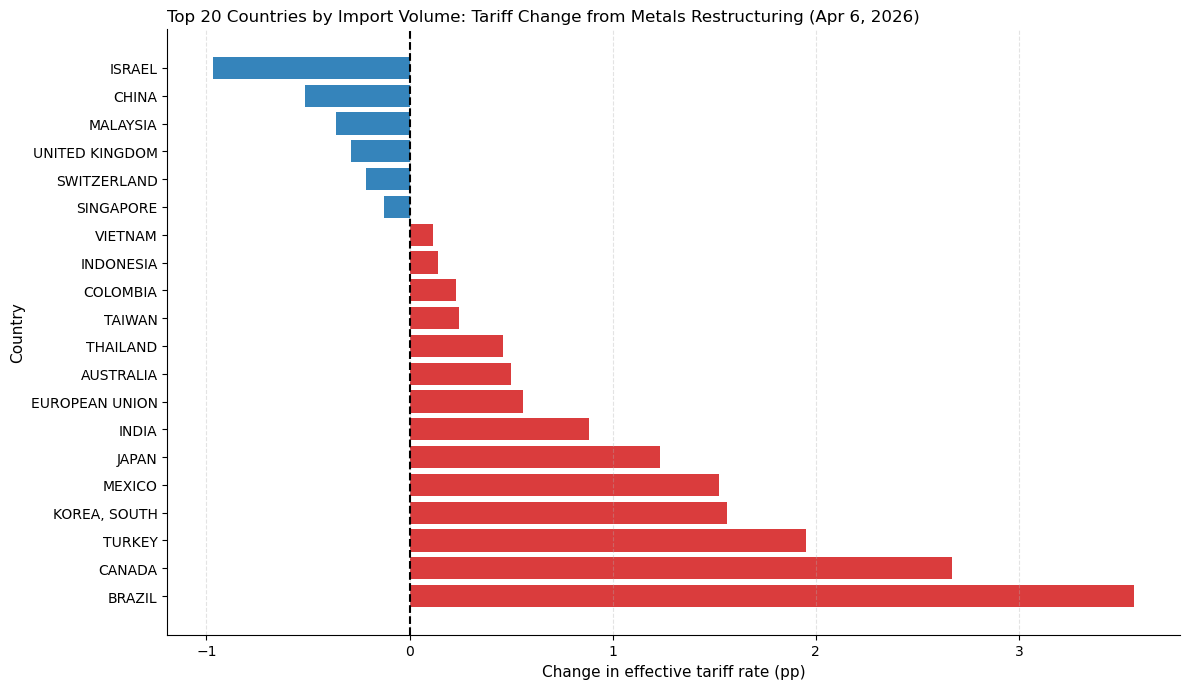

In [29]:
PRE_DATE = pd.to_datetime("2026-02-24")   # Section 122 baseline
POST_DATE = pd.to_datetime("2026-04-06")   # After metals restructuring
TOP_X = 20

panel = tariffs_by_date.reset_index().copy()

pre_vals = (
    panel.loc[panel['date'] == PRE_DATE, ['country_name', 'effective tariff']]
    .rename(columns={'effective tariff': 'pre_tariff'})
)
post_vals = (
    panel.loc[panel['date'] == POST_DATE, ['country_name', 'effective tariff']]
    .rename(columns={'effective tariff': 'post_tariff'})
)

# Import weights
rows_imp = []
for _, row in country_list.iterrows():
    df_imp = load_imports(row['CTY_CODE'], year=WEIGHT_YEAR)
    rows_imp.append({
        'country_name': df_imp['CTY_NAME'].iloc[0] if 'CTY_NAME' in df_imp.columns else row.get('CTY_NAME', ''),
        'imports_2024': df_imp['imports'].sum(),
    })
imports_wt = pd.DataFrame(rows_imp)

exclude = { }

chg = (
    pre_vals.merge(post_vals, on='country_name', how='inner')
    .merge(imports_wt, on='country_name', how='left')
    .loc[lambda d: ~d['country_name'].str.upper().isin(exclude)]
    .assign(change=lambda d: d['post_tariff'] - d['pre_tariff'])
    .dropna(subset=['imports_2024'])
    .sort_values('imports_2024', ascending=False)
    .head(TOP_X)
    .sort_values('change', ascending=False)
)

fig, ax = plt.subplots(figsize=(12, max(7, 0.35 * TOP_X)))
colors = np.where(chg['change'] >= 0, 'tab:red', 'tab:blue')
ax.barh(chg['country_name'], chg['change'], color=colors, alpha=0.9)
ax.axvline(0, color='black', linewidth=1.5, linestyle='--')

ax.set_xlabel('Change in effective tariff rate (pp)', fontsize=11)
ax.set_ylabel('Country', fontsize=11)
ax.set_title(
    f'Top {TOP_X} Countries by Import Volume: Tariff Change from Metals Restructuring (Apr 6, 2026)',
    fontsize=12, loc='left',
)
ax.grid(axis='x', linestyle='--', alpha=0.35)
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.tight_layout()
plt.show()

### Country detail table

In [30]:
detail = (
    decomp_df
    .sort_values('total_imports', ascending=False)
    .head(25)
    [['country', 'total_imports', 'pre_weighted_tariff', 'post_weighted_tariff',
      'tariff_change', 'imports_up', 'imports_down']]
    .copy()
)
detail.columns = ['Country', 'Total Imports', 'Pre Rate', 'Post Rate',
                   'Change (pp)', 'Imports Up', 'Imports Down']

print("Top 25 countries — effective tariff change from metals restructuring:")
print(detail.to_string(index=False, float_format='{:.2f}'.format))

Top 25 countries — effective tariff change from metals restructuring:
       Country   Total Imports  Pre Rate  Post Rate  Change (pp)     Imports Up   Imports Down
EUROPEAN UNION 597473236377.00      8.50       8.94         0.44 41343246898.00 25643816116.00
        MEXICO 503438605302.00      6.13       7.60         1.47 40681076408.00 13272758784.00
         CHINA 429425828419.00     10.88      10.19        -0.69 28043192993.00 31238311775.00
        CANADA 411693824741.00      2.98       5.64         2.65 32153491523.00  3719245154.00
         JAPAN 151340030810.00     11.95      12.70         0.75 17186273331.00  7259155376.00
       VIETNAM 141361159091.00      8.26       8.24        -0.02  5565108729.00  4790334308.00
  KOREA, SOUTH 130458735626.00     11.48      12.88         1.40 15915984915.00  5865791392.00
        TAIWAN 115274122243.00      6.05       5.82        -0.22  4686716240.00  4708615352.00
         INDIA  87735219365.00      8.71       9.58         0.87  596810373